# Supplementary figure: marker genes of the cell type annotation

Dot plots of canonical marker genes for the cell types of the lung and blood single-cell data.
For each cell type and gene, the dot colour shows the mean expression (scaled to 0-1 per gene) and the dot size the fraction of expressing cells.
These summaries were extracted from the single-cell objects in `00_prepare_tables_from_raw_data.ipynb` and are plotted here with scanpy's `DotPlot`,
giving the same figure as `sc.pl.dotplot(adata, var_names, groupby, log=True, standard_scale="var")` on the full data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
from anndata import AnnData

from figure_style import DOTPLOT_LEGEND_MM, DENSE_FONT_SIZE, FONT_SIZE, add_dotplot_legends, figure_size, fit_dots_to_cells, save_panel, set_style, thin_scanpy_lines

set_style()
DATA = Path("../data")


def flatten_markers(marker_genes):
    """Genes in plotting order (DotPlot reads precomputed tables by column position, so columns must follow var_names)."""
    return [gene for genes in marker_genes.values() for gene in genes]



def marker_dotplot(mean_file, fraction_file, marker_genes, groups_order, name, height_mm, group_label_size=FONT_SIZE):
    mean = pd.read_csv(DATA / mean_file, index_col=0)
    fraction = pd.read_csv(DATA / fraction_file, index_col=0)

    # Scale mean expression to 0-1 per gene, as scanpy does with standard_scale="var"
    scaled_mean = mean - mean.min(axis=0)
    scaled_mean = (scaled_mean / scaled_mean.max(axis=0)).fillna(0)

    # One "observation" per cell type; the plotted values come from the precomputed tables
    adata = AnnData(
        X=scaled_mean.values,
        obs=pd.DataFrame({"cell_type": pd.Categorical(scaled_mean.index)}, index=scaled_mean.index.rename(None)),
        var=pd.DataFrame(index=scaled_mean.columns),
    )
    with plt.rc_context({"xtick.labelsize": DENSE_FONT_SIZE, "font.size": group_label_size}):  # Gene names and marker group labels
        width_mm = 183 - DOTPLOT_LEGEND_MM
        dot_plot = sc.pl.DotPlot(
            adata, var_names=marker_genes, groupby="cell_type", categories_order=groups_order,
            dot_color_df=scaled_mean.loc[:, flatten_markers(marker_genes)], dot_size_df=fraction.loc[:, flatten_markers(marker_genes)],
            figsize=figure_size(width_mm, height_mm),
        )
        dot_plot.style(cmap="Reds", dot_edge_lw=0.3, dot_max=1, dot_min=0, smallest_dot=0)
        dot_plot.legend(show=False)
        dot_plot.make_figure()
        fit_dots_to_cells(dot_plot)  # Size the dots from the laid-out axes so they never overflow their cells
        thin_scanpy_lines(dot_plot)
        add_dotplot_legends(dot_plot, colorbar_title="Mean expression\nin group (scaled)")
        save_panel(name)
        plt.show()

## Lung

In [2]:
lung_marker_genes = {
    "AT1": ["AGER"],
    "AT2": ["SFTPC"],
    "AT2_B": ["SFTPA1", "SFTPD"],
    "AT2_S": ["ERBB4"],
    "Basal": ["KRT5"],
    "Ciliated_cells": ["SNTN"],
    "Club_cells": ["SCGB1A1"],
    "TASC": ["SCGB3A2", "SFTPB"],
    "capillary_cells": ["PRX"],
    "aerocytes": ["CA4"],
    "gCaps": ["FCN3"],
    "Endothelial": ["CX3CL1"],
    "Fibroblasts": ["LUM"],
    "SMC": ["ACTA2"],
    "Pericytes": ["COX4I2", "GUCY1A2", "MCAM", "GUCY1B1", "PDGFRB", "EGFL6"],
    "Alveolar macrophages": ["MARCO", "MSR1"],
    "Macrophages_APOE+": ["APOE", "MMP9", "PLA2G7"],
    "Intersticial macrophages": ["CD163"],
    "Monocytes_Classical": ["CD14", "SERPINB2", "CD163", "FABP4"],
    "Monocytes_Non-classical": ["CDKN1C", "FCGR3A"],
    "NK-cells": ["GZMB", "KIR2DL4"],
    "T-cells": ["CD3E", "CD4", "CD8A", "FOXP3", "IL17A"],
    "T_CD4": ["CD4"],
    "T_CD8": ["CD8A"],
    "T_reg": ["FOXP3"],
    "Dividing cells": ["CDKN2A"],
    "T_senescence-associated": ["THEMIS", "CTLA4"],
    "B-cells": ["CD19", "CR2", "MS4A1"],
    "Plasma_cells": ["JCHAIN", "IGHG1"],
    "Dendritic_cells": ["IL3RA"],
    "Granulocytes": ["HDC", "MS4A2"],
}

lung_groups_order = [
    # Epithelial
    "AT1", "AT2_B", "AT2_S", "Basal", "Ciliated", "Club cells", "TASC", "Rare",
    # Endothelial
    "Aerocytes", "Artery", "gCaps", "Lymphatic", "HSP_endo", "IL6_endo",
    # Stroma
    "Mesothelium", "SMC", "Pericytes", "Fibroblasts_adventitial", "Fibroblasts_adventitial_lipo", "Fibroblasts_alveolar", "Veins_pulmonary", "Veins_systemic",
    # Immune
    "Macrophages_Alveolar", "Macrophages_Alveolar_APOE", "Macrophages_Interstitial", "Macrophages_Smoking-induced", "Macrophages_div",
    "T_CD4", "T_CD8", "T_div", "T_reg", "T_senescence-associated", "NK",
    "Monocytes_Classical", "Monocytes_Non-Classical",
    "mDC", "pDC", "DC1", "DC2",
    "IGHD+B", "IGHD-B", "Plasma",
    "Mast",
]

/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


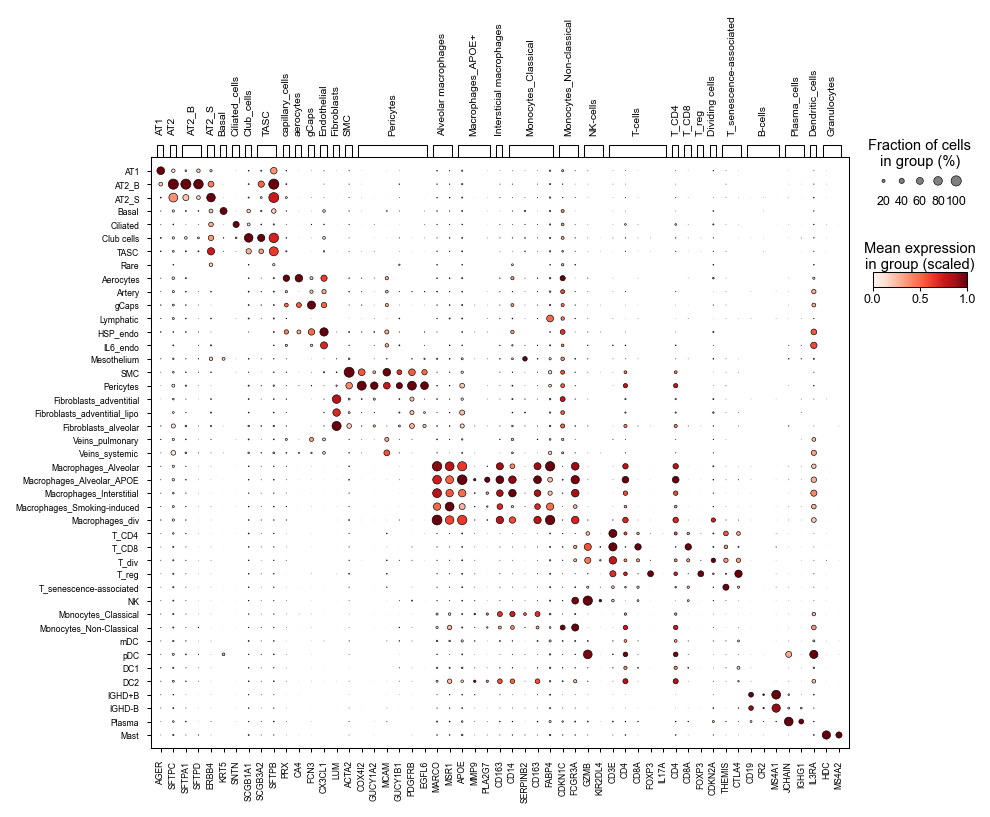

In [3]:
marker_dotplot(
    "18_lung_annotation_markers_mean_expression.csv", "19_lung_annotation_markers_fraction_expressing.csv",
    lung_marker_genes, lung_groups_order, name="Supp_Fig_lung_annotation_markers", height_mm=130, group_label_size=DENSE_FONT_SIZE,
)

## Blood

Markers follow the Azimuth PBMC reference (Hao et al., Cell 2021) and common PBMC annotation practice:
B cells (MS4A1, CD79A), naive B (IGHD, TCL1A), memory B (CD27), plasmablasts (MZB1, JCHAIN, TNFRSF17),
T cells (CD3E, CD2), naive T (CCR7, SELL, LEF1, TCF7), CD4 (CD4, CD40LG) and CD8 (CD8A, CD8B) T cells, central memory (IL7R, LTB, AQP3),
Treg (FOXP3, IL2RA, RTKN2, IKZF2), cytotoxic lymphocytes (GZMA, GZMH, FGFBP2, CCL5), MAIT (KLRB1, SLC4A10), gamma-delta T (TRDC, TRGV9, TRDV2),
ILC (TNFRSF4, TNFRSF18), NK (NKG7, GNLY, KLRF1, KLRD1), CD56-bright NK (NCAM1, XCL1, KLRC1), proliferating cells (MKI67, STMN1, TOP2A),
classical monocytes (LYZ, CD14, S100A8, S100A12, VCAN), non-classical monocytes (FCGR3A, LST1, CDKN1C, MS4A7), cDC (CD1C, FCER1A, CLEC10A),
pDC (IL3RA, LILRA4, CLEC4C, IRF7) and platelets (PPBP, PF4, GP9).
PRMT7+ monocytes are shown with genes of the SIMs signature (LRMDA, PLXDC2, ZEB2) and NEAT1.
The NK_m and dnTorCD8 populations have no specific canonical marker and share NK / T cell markers at a lower level.

In [4]:
blood_marker_genes = {
    "B cells": ["MS4A1", "CD79A"],
    "Naive B": ["IGHD", "TCL1A"],
    "Memory B": ["CD27"],
    "Plasmablast": ["MZB1", "JCHAIN", "TNFRSF17"],
    "T cells": ["CD3E", "CD2"],
    "Naive T": ["CCR7", "SELL", "LEF1", "TCF7"],
    "CD4 T": ["CD4", "CD40LG"],
    "CD8 T": ["CD8A", "CD8B"],
    "CD4 TCM": ["IL7R", "LTB", "AQP3"],
    "Treg": ["FOXP3", "IL2RA", "RTKN2", "IKZF2"],
    "Cytotoxic": ["GZMA", "GZMH", "FGFBP2", "CCL5"],
    "MAIT": ["KLRB1", "SLC4A10"],
    "gdT": ["TRDC", "TRGV9", "TRDV2"],
    "ILC": ["TNFRSF4", "TNFRSF18"],
    "NK": ["NKG7", "GNLY", "KLRF1", "KLRD1"],
    "NK CD56bright": ["NCAM1", "XCL1", "KLRC1"],
    "Proliferating": ["MKI67", "STMN1", "TOP2A"],
    "Monocytes": ["LYZ", "CD14", "S100A8", "S100A12", "VCAN"],
    "Monocytes_PRMT7+": ["LRMDA", "PLXDC2", "ZEB2", "NEAT1"],
    "CD16 monocytes": ["FCGR3A", "LST1", "CDKN1C", "MS4A7"],
    "cDC": ["CD1C", "FCER1A", "CLEC10A"],
    "pDC": ["IL3RA", "LILRA4", "CLEC4C", "IRF7"],
    "Platelet": ["PPBP", "PF4", "GP9"],
}

blood_groups_order = [
    # B lineage
    "Bnaive", "B", "Plasmablast",
    # T cells
    "CD4_Naive", "CD8_Naive", "CD4_TCM", "Treg", "CD4_CTL", "CD8_TEM", "MAIT", "gdT", "ILC",
    # NK cells and related
    "NK", "NK_CD56bright", "NK_m", "dnTorCD8", "T/NK_proliferating",
    # Myeloid
    "CD14", "Monocytes_PRMT7+", "CD16", "cDC", "pDC",
    "Platelet",
]

/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


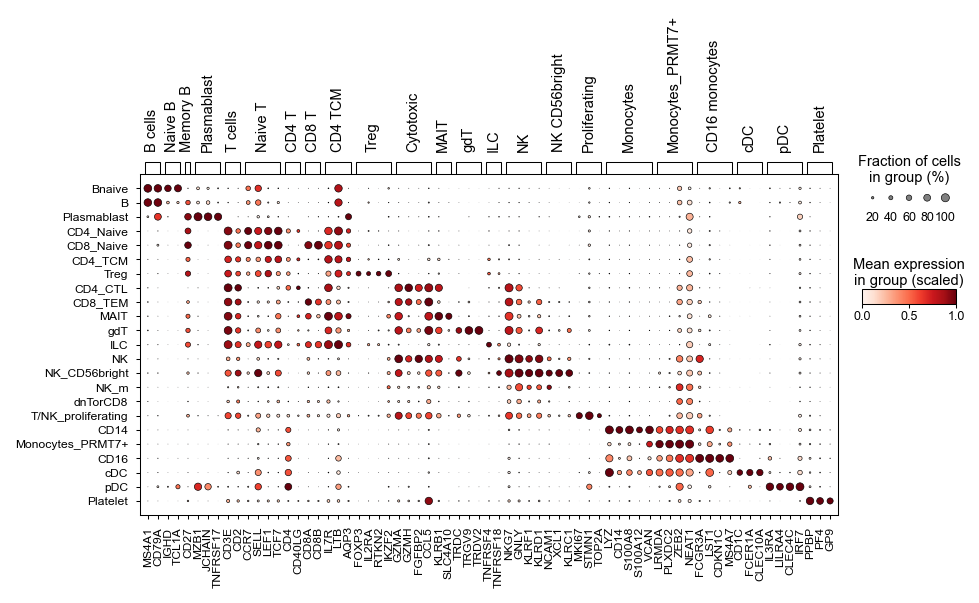

In [5]:
marker_dotplot(
    "20_blood_annotation_markers_mean_expression.csv", "21_blood_annotation_markers_fraction_expressing.csv",
    blood_marker_genes, blood_groups_order, name="Supp_Fig_blood_annotation_markers", height_mm=75,
)